In [55]:
import yfinance as yf
import pandas as pd
import numpy as np 
import time
import matplotlib.pyplot as plt

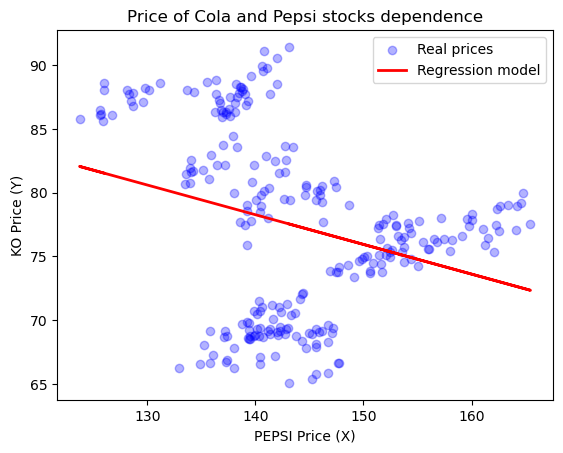

In [67]:
#downloading data from yfinance
df1= yf.download("PEP", period="1y", interval="1d", progress=False)
df2= yf.download("KO", period="1y", interval="1d", progress=False)
close1=df1['Close']
close2=df2['Close']
#checking if there is any missing data
close1.isnull().sum()
close2.isnull().sum()
#merging close1 and close2 vectors into a single matrix 
data=pd.merge(close1 , close2, on="Date")
#PEP will be explanatory variable X and KO explained variable Y
xvar = data[["PEP"]]
yvar = data["KO"]
X=xvar.copy()
Y=yvar.copy()
#adding column of 1's on position 0
X.insert(0, "Constant", 1)
#using numpy library we calculate the OLS estimator - beta hat
beta_hat=np.linalg.inv((X.T)@X)@X.T@Y
y_hat = X.to_numpy() @ beta_hat.to_numpy()
#print(beta_hat)
#print(y_hat)
plt.scatter(X["PEP"], Y, color="blue", alpha=0.3, label="Real prices")
plt.plot(X["PEP"], y_hat, color="red", linewidth=2, label="Regression model")
plt.xlabel("PEPSI Price (X)")
plt.ylabel("KO Price (Y)")
plt.title("Price of Cola and Pepsi stocks dependence")
plt.legend()
plt.show()

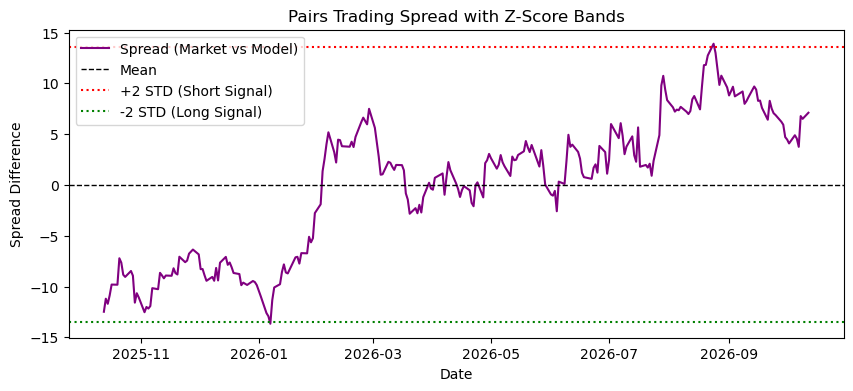

In [72]:
spread = Y.to_numpy().flatten() - y_hat.flatten()
spread_mean = np.mean(spread)
spread_std = np.std(spread)
threshold = 2


plt.figure(figsize=(10, 4))
plt.plot(data.index, spread, color="purple", label="Spread (Market vs Model)")
plt.axhline(spread_mean, color="black", linestyle="--", linewidth=1, label="Mean")

plt.axhline(spread_mean + threshold * spread_std, color="red", linestyle=":", linewidth=1.5, label="+2

            STD (Short Signal)")
plt.axhline(spread_mean - threshold * spread_std, color="green", linestyle=":", linewidth=1.5, label="-2 STD (Long Signal)")

plt.title("Pairs Trading Spread with Z-Score Bands")
plt.xlabel("Date")
plt.ylabel("Spread Difference")
plt.legend()
plt.show()

In [74]:
from statsmodels.tsa.stattools import adfuller

#ADF test on spread vecor
adf_result = adfuller(spread)
p_value = adf_result[1]

print("Augmented Dickey-Fuller Test Results:")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("\nConclusion: The p-value is less than 0.05. The spread is stationary (cointegrated).")
    print("This pair is SUITABLE for statistical arbitrage.")
else:
    print("\nConclusion: The p-value is greater than 0.05. The spread is not stationary.")
    print("This pair is NOT SUITABLE for trading.")

Augmented Dickey-Fuller Test Results:
ADF Statistic: -1.8422
p-value: 0.3597

Conclusion: The p-value is greater than 0.05. The spread is not stationary.
This pair is NOT SUITABLE for trading.
